# Exploratory Double Machine Learning (DML) — Algorithmic Pricing

**Project:** Causal Inference & Synthetic Control Engine for Algorithmic Pricing  
**Dataset:** `project1_algorithmic_pricing_synthetic_dataset.csv`  
**Intervention:** North region, beginning 1 May 2025

> **Interpretation warning:** This notebook implements a cross-fitted partialling-out DML workflow as an exploratory methodological exercise. The dataset has one treated region and treatment is perfectly determined by region × post-period. The resulting lack of treatment overlap means the estimated coefficient must **not** be reported as a validated causal ATE.


## 1. Objective and estimand

We use `revenue` as the outcome (Y) and `treatment` as the binary intervention indicator (D). Candidate pre-treatment/context covariates are competitor price, marketing spend, promotion status, region and calendar features.

We deliberately exclude `our_price` because it is the pricing lever changed by the intervention and may be a mediator; adjusting for it could remove part of the total treatment pathway. We also exclude `units_sold`, which may respond to price and treatment. `product_category` has only one value and carries no information.

The partialling-out score is based on cross-fitted predictions of E[Y|X] and E[D|X]:

`Y_res = Y - m_hat(X)`; `D_res = D - e_hat(X)`; `theta_hat = mean(D_res * Y_res) / mean(D_res**2)`.

This requires conditional exchangeability, adequate overlap/positivity, and appropriate dependence handling. The data design makes overlap particularly problematic.

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.model_selection import GroupKFold
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.metrics import roc_auc_score, mean_squared_error

SEED = 42
TREATMENT_DATE = pd.Timestamp('2025-05-01')
DATA_CANDIDATES = [
    Path('project1_algorithmic_pricing_synthetic_dataset.csv'),
    Path('../project1_algorithmic_pricing_synthetic_dataset.csv'),
    Path('/mnt/data/project1_algorithmic_pricing_synthetic_dataset.csv'),
]
DATA_PATH = next((p for p in DATA_CANDIDATES if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError('Place project1_algorithmic_pricing_synthetic_dataset.csv beside this notebook or update DATA_PATH.')

df = pd.read_csv(DATA_PATH, parse_dates=['date'])
print('Dataset shape:', df.shape)
print('Date range:', df.date.min().date(), 'to', df.date.max().date())
print('Regions:', sorted(df.region.unique()))
print('Missing values:', int(df.isna().sum().sum()))
df.head()

Dataset shape: (540, 11)
Date range: 2025-01-01 to 2025-06-29
Regions: ['North', 'South', 'West']
Missing values: 0


,date,region,product_category,our_price,competitor_price,units_sold,revenue,marketing_spend,promotion_active,treatment,period
0,2025-01-01,North,Home Essentials,501.50,494.80,101,50651.59,474.38,0,0,pre_treatment
1,2025-01-01,South,Home Essentials,489.38,490.19,100,48937.65,417.33,0,0,pre_treatment
2,2025-01-01,West,Home Essentials,509.40,511.37,118,60109.02,449.37,0,0,pre_treatment
3,2025-01-02,North,Home Essentials,499.37,502.85,109,54431.06,345.83,0,0,pre_treatment
4,2025-01-02,South,Home Essentials,486.93,494.56,107,52101.37,381.01,0,0,pre_treatment


## 2. Treatment assignment and data checks

First verify that the supplied treatment flag agrees with the stated intervention definition. This is a design audit, not a model result.

In [2]:
df['expected_treatment'] = ((df['region'] == 'North') & (df['date'] >= TREATMENT_DATE)).astype(int)
print('Treatment flag matches North × post definition:', bool((df.treatment == df.expected_treatment).all()))
print('Treatment counts:', df.treatment.value_counts().sort_index().to_dict())

assignment = (df.groupby(['region', 'period'])
              .agg(observations=('treatment', 'size'), treated_share=('treatment', 'mean'))
              .reset_index())
display(assignment)

print('Unique dates:', df.date.nunique())
print('Rows per date (min/max):', df.groupby('date').size().min(), df.groupby('date').size().max())

Treatment flag matches North × post definition: True
Treatment counts: {0: 480, 1: 60}


,region,period,observations,treated_share
0,North,post_treatment,60,1.0
1,North,pre_treatment,120,0.0
2,South,post_treatment,60,0.0
3,South,pre_treatment,120,0.0
4,West,post_treatment,60,0.0
5,West,pre_treatment,120,0.0


Unique dates: 180
Rows per date (min/max): 3 3


### Treatment overlap warning

All North post-intervention observations are treated; every other region-period cell is untreated. There are no treated South/West observations and no untreated North observations after the intervention. A model that learns region and time patterns can therefore predict treatment almost perfectly. This is a structural design limitation, not something cross-fitting can fix.

treatment                0   1  All
region period                      
North  post_treatment    0  60   60
       pre_treatment   120   0  120
South  post_treatment   60   0   60
       pre_treatment   120   0  120
West   post_treatment   60   0   60
       pre_treatment   120   0  120
All                    480  60  540

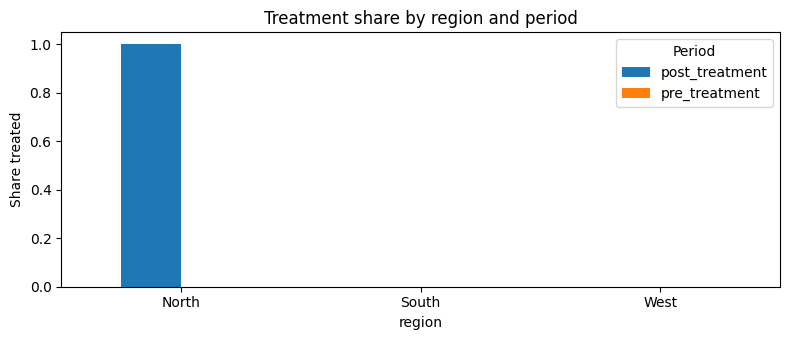

In [3]:
overlap_table = pd.crosstab([df.region, df.period], df.treatment, margins=True)
display(overlap_table)

fig, ax = plt.subplots(figsize=(8, 3.5))
assignment.pivot(index='region', columns='period', values='treated_share').plot(kind='bar', ax=ax)
ax.set_title('Treatment share by region and period')
ax.set_ylabel('Share treated')
ax.set_ylim(0, 1.05)
ax.legend(title='Period')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 3. Define outcome, treatment and covariates

The candidate covariates below are not automatically valid confounders. Their causal timing must be confirmed from the data-generation process or project owner. In particular, marketing spend and promotions could themselves respond to the pricing intervention. We therefore treat the estimates as specification-sensitive diagnostics.

In [4]:
df = df.sort_values(['date', 'region']).reset_index(drop=True).copy()
df['day_index'] = (df['date'] - df['date'].min()).dt.days
df['day_of_week'] = df['date'].dt.dayofweek
df['month'] = df['date'].dt.month

Y = df['revenue'].astype(float).to_numpy()
D = df['treatment'].astype(int).to_numpy()
GROUPS = df['date'].to_numpy()  # keep all regions from a date in the same fold
NUMERIC = ['competitor_price', 'marketing_spend', 'promotion_active', 'day_index', 'day_of_week', 'month']
CATEGORICAL = ['region']
FEATURES = NUMERIC + CATEGORICAL
X = df[FEATURES].copy()

print('Outcome:', 'revenue')
print('Treatment:', 'treatment')
print('Covariates:', FEATURES)
print('Excluded post-treatment / possible mediator variables: our_price, units_sold')

Outcome: revenue
Treatment: treatment
Covariates: ['competitor_price', 'marketing_spend', 'promotion_active', 'day_index', 'day_of_week', 'month', 'region']
Excluded post-treatment / possible mediator variables: our_price, units_sold


## 4. Cross-fitted partialling-out DML

We use grouped five-fold cross-fitting: all three regional rows for a given date remain in the same fold. This reduces leakage across regions on the same date. It does **not** solve serial correlation or the single-treated-region design.

Two nuisance-model specifications are compared:
- **Regularized linear/logistic:** transparent baseline.
- **Random forest:** flexible sensitivity specification.

The reported cluster-by-date standard error is a rough diagnostic. With a single treated region and a deterministic treatment rule, it should not be interpreted as valid design-based causal uncertainty.

In [5]:
numeric_pipe = Pipeline([('imputer', SimpleImputer(strategy='median')), ('scale', StandardScaler())])
categorical_pipe = Pipeline([('imputer', SimpleImputer(strategy='most_frequent')), ('onehot', OneHotEncoder(handle_unknown='ignore'))])
preprocessor = ColumnTransformer([('num', numeric_pipe, NUMERIC), ('cat', categorical_pipe, CATEGORICAL)])

def crossfit_dml(y_model, d_model, label, clip=0.01):
    splitter = GroupKFold(n_splits=5)
    y_hat = np.full(len(df), np.nan)
    d_hat = np.full(len(df), np.nan)
    for train_idx, test_idx in splitter.split(X, D, groups=GROUPS):
        ym = Pipeline([('prep', clone(preprocessor)), ('model', clone(y_model))])
        dm = Pipeline([('prep', clone(preprocessor)), ('model', clone(d_model))])
        ym.fit(X.iloc[train_idx], Y[train_idx])
        dm.fit(X.iloc[train_idx], D[train_idx])
        y_hat[test_idx] = ym.predict(X.iloc[test_idx])
        d_hat[test_idx] = dm.predict_proba(X.iloc[test_idx])[:, 1]

    d_hat_clipped = np.clip(d_hat, clip, 1 - clip)
    y_res = Y - y_hat
    d_res = D - d_hat_clipped
    denom = np.sum(d_res ** 2)
    theta = np.sum(d_res * y_res) / denom
    score = d_res * (y_res - theta * d_res)
    cluster_scores = pd.DataFrame({'date': GROUPS, 'score': score}).groupby('date').score.sum().to_numpy()
    se_cluster_date = np.sqrt(np.sum(cluster_scores ** 2)) / denom
    auc = roc_auc_score(D, d_hat)
    overlap_share = np.mean((d_hat >= 0.05) & (d_hat <= 0.95))
    return {
        'specification': label, 'theta': float(theta), 'cluster_date_se_diagnostic': float(se_cluster_date),
        'ci_low_diagnostic': float(theta - 1.96 * se_cluster_date),
        'ci_high_diagnostic': float(theta + 1.96 * se_cluster_date),
        'propensity_auc': float(auc), 'share_propensity_0.05_to_0.95': float(overlap_share),
        'propensity': d_hat, 'y_hat': y_hat, 'd_hat': d_hat, 'y_res': y_res, 'd_res': d_res
    }

linear_result = crossfit_dml(
    Ridge(alpha=10.0), LogisticRegression(C=0.1, max_iter=3000, solver='lbfgs'), 'Ridge + logistic'
)
forest_result = crossfit_dml(
    RandomForestRegressor(n_estimators=300, min_samples_leaf=5, max_features=0.8, random_state=SEED, n_jobs=-1),
    RandomForestClassifier(n_estimators=300, min_samples_leaf=5, max_features=0.8, random_state=SEED, n_jobs=-1),
    'Random forest + random forest'
)

results = pd.DataFrame([{k: r[k] for k in ['specification','theta','cluster_date_se_diagnostic','ci_low_diagnostic','ci_high_diagnostic','propensity_auc','share_propensity_0.05_to_0.95']} for r in [linear_result, forest_result]])
display(results.style.format({c: '{:.4f}' for c in results.select_dtypes('number').columns}))

,specification,theta,cluster_date_se_diagnostic,ci_low_diagnostic,ci_high_diagnostic,propensity_auc,share_propensity_0.05_to_0.95
0,Ridge + logistic,875.4821,1054.5586,-1191.4528,2942.4170,1.0000,0.4556
1,Random forest + random forest,10001.9474,4813.2653,567.9475,19435.9474,1.0000,0.0093


## 5. Positivity / propensity diagnostics

A propensity score near zero or one means the model sees little comparable treatment status at those covariate values. The share in the 0.05–0.95 interval is a simple diagnostic, not a universal pass/fail threshold.

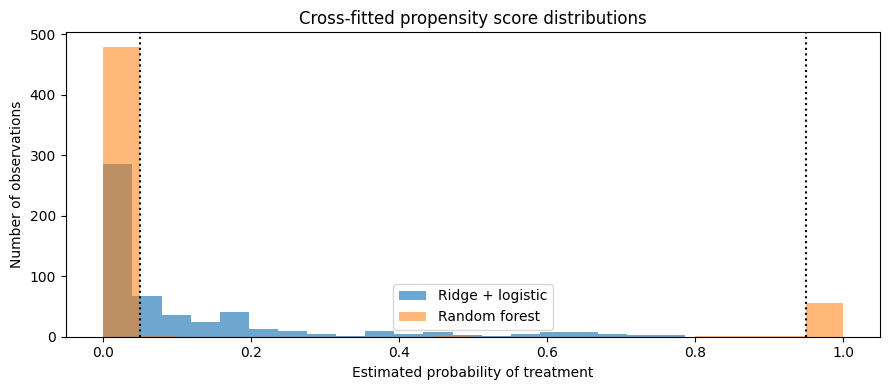

Ridge + logistic propensity quantiles: [0.0009 0.001  0.0017 0.0312 0.3619 0.716  0.787 ]
Random forest propensity quantiles: [0.     0.     0.     0.     0.9786 1.     1.    ]
Ridge + logistic propensity range — treated: [0.2959, 0.7870], controls: [0.0009, 0.2790], common-support interval: [0.2959, 0.2790]
Random forest propensity range — treated: [0.4898, 1.0000], controls: [0.0000, 0.0887], common-support interval: [0.4898, 0.0887]


In [6]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(linear_result['propensity'], bins=20, alpha=0.65, label='Ridge + logistic')
ax.hist(forest_result['propensity'], bins=20, alpha=0.55, label='Random forest')
ax.axvline(0.05, color='black', linestyle=':')
ax.axvline(0.95, color='black', linestyle=':')
ax.set_title('Cross-fitted propensity score distributions')
ax.set_xlabel('Estimated probability of treatment')
ax.set_ylabel('Number of observations')
ax.legend()
plt.tight_layout()
plt.show()

for name, r in [('Ridge + logistic', linear_result), ('Random forest', forest_result)]:
    q = np.quantile(r['propensity'], [0, .01, .1, .5, .9, .99, 1])
    print(name, 'propensity quantiles:', np.round(q, 4))

for name, r in [('Ridge + logistic', linear_result), ('Random forest', forest_result)]:
    treated_scores = r['propensity'][D == 1]
    control_scores = r['propensity'][D == 0]
    common_low = max(treated_scores.min(), control_scores.min())
    common_high = min(treated_scores.max(), control_scores.max())
    print(f"{name} propensity range — treated: [{treated_scores.min():.4f}, {treated_scores.max():.4f}], controls: [{control_scores.min():.4f}, {control_scores.max():.4f}], common-support interval: [{common_low:.4f}, {common_high:.4f}]")

## 6. Interpretation and decision

The DML coefficient is the residual-on-residual partialling-out estimate under the selected nuisance models. In this dataset, the treatment propensity model can distinguish treated from untreated observations extremely well, leaving very little residual treatment variation. That is a warning sign for weak overlap and extrapolation.

**Do not describe either coefficient or its diagnostic interval as a validated causal ATE.** The estimate is sensitive to nuisance-model specification and the data contain only one treated region. A reliable design would need multiple treated and untreated markets with comparable pre/post periods, plus a defensible set of pre-treatment confounders.

In [7]:
diagnostics = pd.DataFrame([
    {'check': 'Number of treated regions', 'result': int(df.loc[df.treatment == 1, 'region'].nunique())},
    {'check': 'Number of untreated regions', 'result': int(df.loc[df.treatment == 0, 'region'].nunique())},
    {'check': 'Treated observations', 'result': int(D.sum())},
    {'check': 'Untreated observations', 'result': int((1-D).sum())},
    {'check': 'Unique dates', 'result': int(df.date.nunique())},
    {'check': 'Product categories', 'result': int(df.product_category.nunique())},
])
display(diagnostics)

print('Exploratory DML estimates (revenue units):')
for r in [linear_result, forest_result]:
    print(f"{r['specification']}: theta={r['theta']:.2f}; date-cluster SE diagnostic={r['cluster_date_se_diagnostic']:.2f}; propensity AUC={r['propensity_auc']:.3f}; overlap share={r['share_propensity_0.05_to_0.95']:.1%}")
print('Conclusion: insufficient overlap and only one treated region; no validated causal ATE/CATE is claimed.')

,check,result
0,Number of treated regions,1
1,Number of untreated regions,3
2,Treated observations,60
3,Untreated observations,480
4,Unique dates,180
5,Product categories,1


Exploratory DML estimates (revenue units):
Ridge + logistic: theta=875.48; date-cluster SE diagnostic=1054.56; propensity AUC=1.000; overlap share=45.6%
Random forest + random forest: theta=10001.95; date-cluster SE diagnostic=4813.27; propensity AUC=1.000; overlap share=0.9%
Conclusion: insufficient overlap and only one treated region; no validated causal ATE/CATE is claimed.


## 7. Limitations and next steps

1. **One treated region:** North is the only treated market. Daily rows do not create independent treated markets.
2. **Deterministic assignment:** treatment equals North × post-intervention. Propensity overlap is weak or absent.
3. **Potential post-treatment controls:** marketing spend and promotion status need data-generation documentation to establish whether they are pre-treatment confounders or treatment responses.
4. **Time dependence:** grouped date folds prevent same-date leakage but do not fully model serial dependence.
5. **CATE not estimated:** the sample/design does not support credible heterogeneous-effect estimation.
6. **Synthetic data:** all results are methodological demonstrations, not evidence of actual commercial impact.

**Recommended data improvement:** add multiple treated and comparison regions, longer pre/post windows, and documented treatment-assignment and covariate timing. Then pre-register the estimand and covariate set, use a design-aware inference procedure, and revisit DML.

### Project status

This notebook demonstrates a reproducible exploratory DML workflow and, importantly, diagnoses why the current dataset is not sufficient for a defensible causal ATE/CATE claim.